In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import confusion_matrix, classification_report

In [2]:
data = pd.read_csv('creditcard.csv')

data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
X = data.drop('Class', axis=1)
y = data['Class']

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42, 
    stratify=y
)

In [5]:
x_train_normal = X_train[y_train == 0]

print(x_train_normal.shape)

(227451, 30)


In [6]:
#before training autoencoder, I need to scale the data
scaler = StandardScaler()

x_train_normal = scaler.fit_transform(x_train_normal)
x_test = scaler.transform(X_test)

In [8]:
autoencoder = Sequential([
    Input(shape=(x_train_normal.shape[1],)),

    #encoder
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),

    #decoder
    Dense(16, activation='relu'),
    Dense(32, activation='relu'),
    Dense(x_train_normal.shape[1], activation='linear')
])

In [11]:
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [13]:
history = autoencoder.fit(
    x_train_normal,
    x_train_normal,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    shuffle=True
)

Epoch 1/10
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - loss: 0.3880 - mae: 0.4259 - val_loss: 0.4019 - val_mae: 0.4366
Epoch 2/10
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - loss: 0.3577 - mae: 0.4101 - val_loss: 0.3402 - val_mae: 0.4044
Epoch 3/10
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 21s 4ms/step - loss: 0.3393 - mae: 0.4003 - val_loss: 0.3214 - val_mae: 0.3934
Epoch 4/10
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 21s 4ms/step - loss: 0.3250 - mae: 0.3929 - val_loss: 0.3137 - val_mae: 0.3899
Epoch 5/10
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 21s 4ms/step - loss: 0.3153 - mae: 0.3878 - val_loss: 0.3025 - val_mae: 0.3850
Epoch 6/10
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 21s 4ms/step - loss: 0.3079 - mae: 0.3839 - val_loss: 0.2950 - val_mae: 0.3806
Epoch 7/10
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 20s 4ms/step - loss: 0.3001 - mae: 0.3791 - val_loss: 0.2927 - val_mae: 0.3772
Epoch 8/10
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 21s 4ms/step - loss: 0.2963 - mae: 0.3759 - val_loss: 0.2850 - val_mae: 0.3725
Epoch 9/10
3199/3199 ━━━━━━━━━━━

In [14]:
train_pred = autoencoder.predict(x_train_normal, verbose=0)

train_error = np.mean(
    np.square(x_train_normal - train_pred),
    axis=1
)

#use train_error to find the threshold
threshold = np.percentile(train_error, 95)
print("\nThreshold: ", threshold)

test_pred = autoencoder.predict(x_test, verbose=0)

test_error = np.mean(
    np.square(x_test - test_pred),
    axis=1
)

y_pred = (test_error > threshold).astype(int)

print("\nFirst 20 predictions: ")
print(y_pred[:20])


Threshold:  0.7809207255506101

First 20 predictions: 
[0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]



Confusion matrix: 
[[53989  2875]
 [   13    85]]

Classification Report: 
              precision    recall  f1-score   support

      Normal       1.00      0.95      0.97     56864
       Fraud       0.03      0.87      0.06        98

    accuracy                           0.95     56962
   macro avg       0.51      0.91      0.51     56962
weighted avg       1.00      0.95      0.97     56962



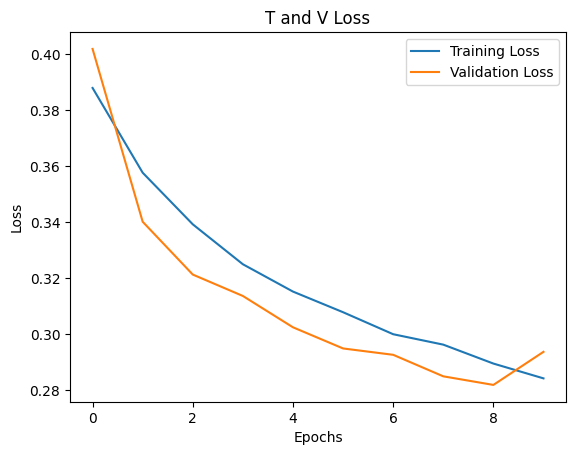

In [18]:
print("\nConfusion matrix: ")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report: ")
print(classification_report(y_test, y_pred, target_names=['Normal', 'Fraud'], zero_division=0))

plt.plot(history.history['loss'], label = "Training Loss")
plt.plot(history.history['val_loss'], label = "Validation Loss")
plt.title("T and V Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.show()